In [24]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self.grad=0.0

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        return Value(self.data + other.data, (self, other), '+')

    def __mul__(self, other):
        return Value(self.data * other.data, (self, other), '*')
    def tanh(self):
        x=self.data
        t=(math.exp(2*x)-1)/(math.exp(2*x)-1)
        out=Value(t, (self,), 'tanh')
        return out
        

In [7]:
# Visualizing the expression graph
from graphviz import Digraph

In [20]:
from graphviz import Digraph

def trace(root):
    """Walk backwards from root, collecting every node and edge."""
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # left to right
    nodes, edges = trace(root)

    for n in nodes:
        uid = str(id(n))
        # a box showing the label and the value
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # a small extra node for the operation (+ or *)
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect the child to the operation node of its parent
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot


a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')

e = a * b;  e.label = 'e'
d = e + c;  d.label = 'd'
f=Value(-2.0, label='f')
L=d*f; L.label='L'

dot = draw_dot(d)
# dot.render('graph', view=True)   # writes graph.svg and opens it
# In Jupyter, just end the cell with:  draw_dot(d)
L

Value(data=-8.0)

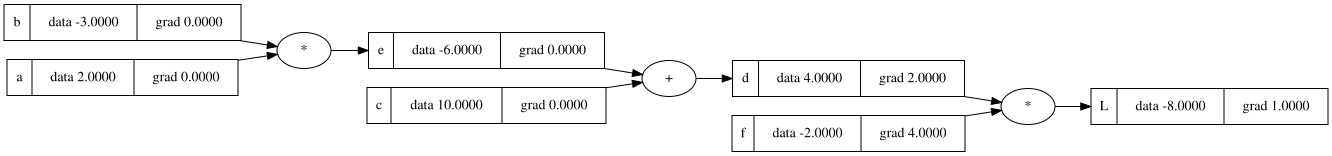

In [10]:
draw_dot(L)

# 00:32:10 manual backpropagation example #1: simple expression

grad==0.0 initially means, the derivative of L with respect to [c, e, d, f]

In [9]:
L.grad=1.0
# dL/df
# L=d*f
# dL/dd=f=-2.0
# dL/df=2*(-3.0) + 10=4
d.grad=2.0
f.grad=4
dL/de=?
we know how L changed with respect to d and f, but not how it did so wrt to e and f directly, but there is a relationship between d and e, itmeans e got to be related to L

de/dd?
dL/de=yes
dL/de?
dL/de=dL/de * de/dd
# same thing applies by symmetry

In [21]:
# starting from L, if change L with a tiny amount h, how much does L, change?
# changes by h, its propotional and ther derivative will eb one


def lol():
    h=0.001
    a=Value(2.0, label='a')
    b=Value(-3.0, label='b')
    c=Value(10.0, label='c')
    e=a*b; e.label='e'
    d=e+c; d.label='d'
    f=Value(-2.0, label='f')
    L=d*f;  L.label='L'
    L1=L.data

    a=Value(2.0, label='a')
    b=Value(-3.0, label='b')
    c=Value(10.0, label='c')
    e=a*b; e.label='e'
    d=e+c; d.label='d'
    f=Value(-2.0, label='f')
    L=d*f;  L.label='L'
    L2=L.data +h

    print((L2-L1)/h)
# lol()
# derivative of a with respect to L   becuae a is the one we bump by h

In [40]:
lol()

1.000000000000334


In [22]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

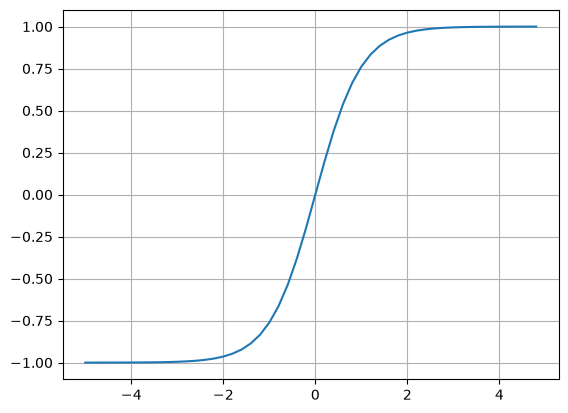

In [14]:
# reak backpropagation

plt.plot(np.arange(-5, 5, 0.2), np.tanh(np.arange(-5, 5, 0.2))); plt.grid();

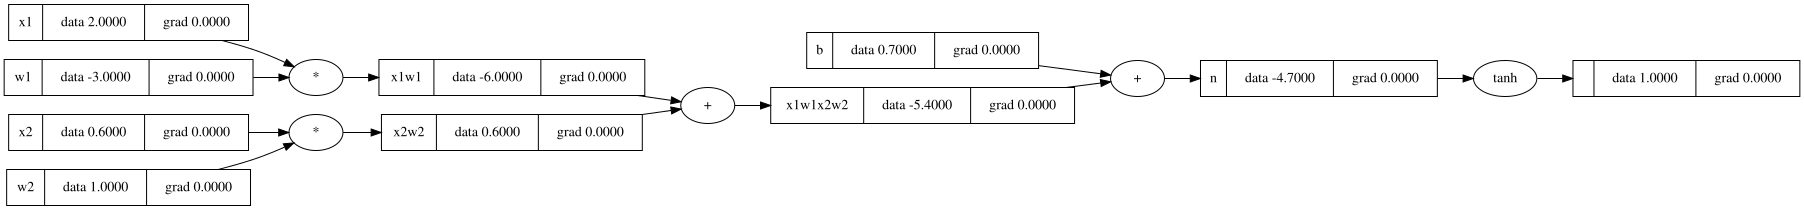

In [25]:
x1=Value(2.0, label='x1')
x2=Value(0.6, label='x2')
#  weigghts [w1, w2]
w1=Value(-3.0, label='w1')
w2=Value(1.0,  label='w2')
# biase of the neuron:
b=Value(0.7, label='b')
# x1w1 + x2w2 + b
x1w1=x1*w1;  x1w1.label='x1w1'
x2w2=x2*w2; x2w2.label='x2w2'
x1w1x2w2=x1w1 + x2w2; x1w1x2w2.label='x1w1x2w2'
n=x1w1x2w2 + b; n.label='n'
o=n.tanh()
draw_dot(o)